In [ ]:
! pip install tensorflow

In [1]:
# Import required libraries
import tensorflow as tf
import pandas as pd
import matplotlib.pyplot as plt


In [2]:

# Read in the insurance dataset
insurance = pd.read_csv("insurance.csv")
insurance.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [3]:
insurance.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [4]:
# Check out the insurance dataset
insurance.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [ ]:
df.isnull().sum()

In [5]:
# Turn all categories into numbers
df = pd.get_dummies(insurance)
df.head() # view the converted columns

,age,bmi,children,charges,sex_female,sex_male,smoker_no,smoker_yes,region_northeast,region_northwest,region_southeast,region_southwest
0,19,27.900,0,16884.92400,True,False,False,True,False,False,False,True
1,18,33.770,1,1725.55230,False,True,True,False,False,False,True,False
2,28,33.000,3,4449.46200,False,True,True,False,False,False,True,False
3,33,22.705,0,21984.47061,False,True,True,False,False,True,False,False
4,32,28.880,0,3866.85520,False,True,True,False,False,True,False,False


In [6]:
# Create X & y values
X = df.drop("charges", axis=1)
y = df["charges"]

In [7]:
# View features
X.head()

,age,bmi,children,sex_female,sex_male,smoker_no,smoker_yes,region_northeast,region_northwest,region_southeast,region_southwest
0,19,27.900,0,True,False,False,True,False,False,False,True
1,18,33.770,1,False,True,True,False,False,False,True,False
2,28,33.000,3,False,True,True,False,False,False,True,False
3,33,22.705,0,False,True,True,False,False,True,False,False
4,32,28.880,0,False,True,True,False,False,True,False,False


In [8]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled[1:10,:]

array([[-1.50996545,  0.5096211 , -0.07876719, -0.98959079,  0.98959079,
         0.5074631 , -0.5074631 , -0.56526686, -0.56641788,  1.63579466,
        -0.56641788],
       [-0.79795355,  0.38330685,  1.58092576, -0.98959079,  0.98959079,
         0.5074631 , -0.5074631 , -0.56526686, -0.56641788,  1.63579466,
        -0.56641788],
       [-0.4419476 , -1.30553108, -0.90861367, -0.98959079,  0.98959079,
         0.5074631 , -0.5074631 , -0.56526686,  1.76548098, -0.61132367,
        -0.56641788],
       [-0.51314879, -0.29255641, -0.90861367, -0.98959079,  0.98959079,
         0.5074631 , -0.5074631 , -0.56526686,  1.76548098, -0.61132367,
        -0.56641788],
       [-0.58434998, -0.80765608, -0.90861367,  1.0105187 , -1.0105187 ,
         0.5074631 , -0.5074631 , -0.56526686, -0.56641788,  1.63579466,
        -0.56641788],
       [ 0.48366788,  0.45548642, -0.07876719,  1.0105187 , -1.0105187 ,
         0.5074631 , -0.5074631 , -0.56526686, -0.56641788,  1.63579466,
        -0.566

In [9]:
y.head()

0    16884.92400
1     1725.55230
2     4449.46200
3    21984.47061
4     3866.85520
Name: charges, dtype: float64

In [10]:
# Create training and test sets
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X_scaled,
                                                    y,
                                                    test_size=0.2,
                                                    random_state=42) # set random state for reproducible splits

In [11]:
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(1070, 11) (268, 11) (1070,) (268,)


In [12]:
# Set random seed
#tf.random.set_seed(42)

# Create a new model (same as model_2)
insurance_model = tf.keras.Sequential([
  tf.keras.layers.Dense(11),
  tf.keras.layers.Dense(1)
])

# Compile the model
insurance_model.compile(loss=tf.keras.losses.mae,
                        optimizer=tf.keras.optimizers.SGD(),
                        metrics=['mae'])

In [13]:
# Fit the model
insurance_model.fit(X_train, y_train, epochs=100)

Epoch 1/100
34/34 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 13345.7012 - mae: 13345.7012
Epoch 2/100
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 13344.7344 - mae: 13344.7344
Epoch 3/100
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 13343.3594 - mae: 13343.3594
Epoch 4/100
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 13341.0898 - mae: 13341.0898
Epoch 5/100
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 13336.9971 - mae: 13336.9971
Epoch 6/100
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 13329.3105 - mae: 13329.3105
Epoch 7/100
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 13314.5469 - mae: 13314.5469
Epoch 8/100
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 13285.8379 - mae: 13285.8379
Epoch 9/100
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 13229.6191 - mae: 13229.6191
Epoch 10/100
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 13119.4336 - mae: 13119.4336
Epoch 11/100
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 12903.0713 - mae: 12903.0713
Epoch 12/100
34/34 ━━━━━━━━━━━

In [14]:
mae_values = insurance_model.history.history['mae']
len(mae_values)

100

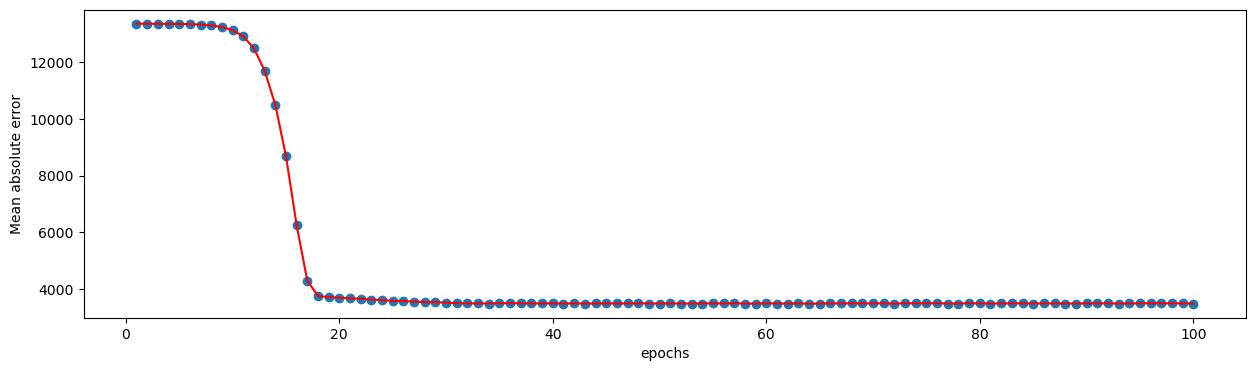

In [15]:
# see the error how it is reduced to minimum times for epoch=5
import matplotlib.pyplot as plt
plt.figure(figsize=(15, 4))
plt.scatter(range(1,101),mae_values)
plt.plot(range(1,101),mae_values,color='red')
plt.ylabel("Mean absolute error")
plt.xlabel("epochs")
plt.show()





```
`# This is formatted as code`
```

 after looking at the graph , the error is not reducing after sometime....and its became consistent which is not use.

Our model didn't perform very well, let's try a bigger model.

We'll try 3 things:

Increasing the number of layers (2 -> 3).

Increasing the number of units in each layer (except for the output layer).

Changing the optimizer (from SGD to Adam).

In [16]:
# Set random seed
tf.random.set_seed(24)

# Add an extra layer and increase number of units
insurance_model_2 = tf.keras.Sequential([
  tf.keras.layers.Dense(11), # 100 units
  tf.keras.layers.Dense(15), # 10 units
  tf.keras.layers.Dense(1) # 1 unit (important for output layer)
])

# Compile the model
insurance_model_2.compile(loss=tf.keras.losses.mae,
                          optimizer=tf.keras.optimizers.Adam(), # Adam automatically adjusts the learning rate for each parameter during trainingworks on Momentum
#RMSProp
                          metrics=['mae'])

#insurance_model_2.compile(loss=tf.keras.losses.mae,
#                          optimizer=tf.keras.optimizers.SGD(), # Stochastic Gradient Descent (SGD) is an optimization algorithm : 
                                                                    # is to reduce error (loss) by updating model weights step by step. Types Batch Gradient and mini batch gradient
#                          metrics=['mae'])


In [17]:
# Fit the model and save the history (we can plot this)
insurance_model_2.fit(X_train, y_train, epochs=200)

Epoch 1/200
34/34 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 13345.9502 - mae: 13345.9502
Epoch 2/200
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 13345.5947 - mae: 13345.5947
Epoch 3/200
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 13345.1357 - mae: 13345.1357
Epoch 4/200
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 13344.4307 - mae: 13344.4307
Epoch 5/200
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 13343.2910 - mae: 13343.2910
Epoch 6/200
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 13341.4229 - mae: 13341.4229
Epoch 7/200
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 13338.4600 - mae: 13338.4600
Epoch 8/200
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 13333.9541 - mae: 13333.9541
Epoch 9/200
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 13327.4229 - mae: 13327.4229
Epoch 10/200
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 13318.4082 - mae: 13318.4082
Epoch 11/200
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 13306.4902 - mae: 13306.4902
Epoch 12/200
34/34 ━━━━━━━━━━━

In [18]:
# prompt: show me the .compile all hyper parameters

insurance_model_2.compile(loss=tf.keras.losses.mae,
                          optimizer=tf.keras.optimizers.Adam(), # Adam works but SGD doesn't
                          metrics=['mae'])

print(insurance_model_2.compile)


<bound method Trainer.compile of <Sequential name=sequential_1, built=True>>


In [19]:
mae_values = insurance_model_2.history.history['mae']
len(mae_values)

200

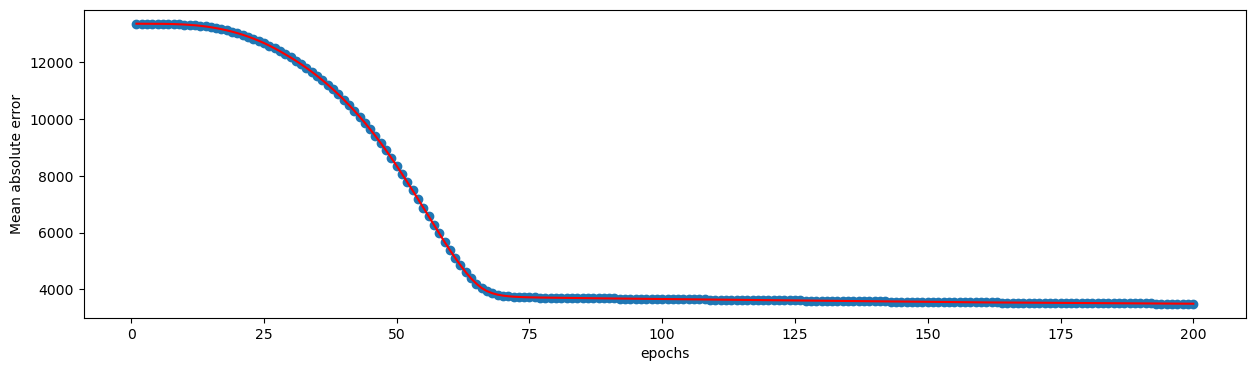

In [20]:
# see the error how it is reduced to minimum times for epoch=5
import matplotlib.pyplot as plt
plt.figure(figsize=(15, 4))
plt.scatter(range(1,201),mae_values)
plt.plot(range(1,201),mae_values,color='red')
plt.ylabel("Mean absolute error")
plt.xlabel("epochs")
plt.show()



In [21]:
insurance_model_2.evaluate(X_test, y_test)

9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 3200.4685 - mae: 3200.4685 


[3200.468505859375, 3200.468505859375]